In [112]:
import os
import pandas as pd

# Find the dataset files
for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

/kaggle/input/datasets/sssonnn/banking77/dev.csv
/kaggle/input/datasets/sssonnn/banking77/train.csv
/kaggle/input/datasets/sssonnn/banking77/test.csv


In [113]:
train_df = pd.read_csv('/kaggle/input/datasets/sssonnn/banking77/train.csv')
dev_df = pd.read_csv('/kaggle/input/datasets/sssonnn/banking77/dev.csv')
test_df = pd.read_csv('/kaggle/input/datasets/sssonnn/banking77/test.csv')
dev_df.head()



print("\nTraining shape:", train_df.shape)
print("Development shape:", dev_df.shape)
print("Test shape:", test_df.shape)


Training shape: (10003, 3)
Development shape: (3080, 3)
Test shape: (3080, 3)


In [114]:
# Training data
X_train = train_df["text"]
y_train = train_df["label"]

# Development data
X_dev = dev_df["text"]
y_dev = dev_df["label"]

# Test data — keep it untouched until final evaluation
X_test = test_df["text"]
y_test = test_df["label"]

# Logistic Regression 

In [115]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2
    )),
    ("classifier", LogisticRegression(max_iter=2000))
])

model.fit(X_train, y_train)

Pipeline(steps=[('tfidf', TfidfVectorizer(min_df=2, ngram_range=(1, 2))),
                ('classifier', LogisticRegression(max_iter=2000))])

In [116]:
print("Training columns:", train_df.columns.tolist())
print("\nFirst 5 rows:")
display(train_df.head())

print("\nTraining shape:", train_df.shape)
print("Development shape:", dev_df.shape)
print("Test shape:", test_df.shape)

Training columns: ['text', 'label', 'label_text']

First 5 rows:


,text,label,label_text
0,I am still waiting on my card?,11,card_arrival
1,What can I do if my card still hasn't arrived ...,11,card_arrival
2,I have been waiting over a week. Is the card s...,11,card_arrival
3,Can I track my card while it is in the process...,11,card_arrival
4,"How do I know if I will get my card, or if it ...",11,card_arrival



Training shape: (10003, 3)
Development shape: (3080, 3)
Test shape: (3080, 3)


In [117]:
from sklearn.metrics import accuracy_score, f1_score

dev_predictions = model.predict(X_dev)

print("Development accuracy:",
      accuracy_score(y_dev, dev_predictions))

print("Development macro F1:",
      f1_score(y_dev, dev_predictions, average="macro"))

Development accuracy: 0.8577922077922078
Development macro F1: 0.8568045932619897


# LinearSVC

In [118]:
from sklearn.svm import LinearSVC
model_svm = Pipeline([('tfidf',TfidfVectorizer(lowercase=True,ngram_range=(1,2),min_df=2)),('classifier',LinearSVC())])

model_svm.fit(X_train,y_train)

Pipeline(steps=[('tfidf', TfidfVectorizer(min_df=2, ngram_range=(1, 2))),
                ('classifier', LinearSVC())])

In [119]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "LinearSVC"],
    "Development Accuracy": [
        accuracy_score(y_dev, model.predict(X_dev)),
        accuracy_score(y_dev, model_svm.predict(X_dev))
    ],
    "Development Macro F1": [
        f1_score(y_dev, model.predict(X_dev), average="macro"),
        f1_score(y_dev, model_svm.predict(X_dev), average="macro")
    ]
})

comparison

,Model,Development Accuracy,Development Macro F1
0,Logistic Regression,0.857792,0.856805
1,LinearSVC,0.889286,0.889269


In [120]:
test_predictions = model_svm.predict(X_test)

print("Test accuracy:",
      accuracy_score(y_test, test_predictions))

print("Test macro F1:",
      f1_score(y_test, test_predictions, average="macro"))

Test accuracy: 0.8892857142857142
Test macro F1: 0.8892685269004629


In [121]:
sample_messages = [
    "I lost my bank card and need a replacement.",
    "I transferred money but it has not arrived.",
    "I want to change my account password."
]

predictions = model_svm.predict(sample_messages)

for message, label in zip(sample_messages, predictions):
    category = train_df.loc[
        train_df["label"] == label, "label_text"
    ].iloc[0]

    print("Message:", message)
    print("Predicted category:", category)
    print()

Message: I lost my bank card and need a replacement.
Predicted category: lost_or_stolen_card

Message: I transferred money but it has not arrived.
Predicted category: transfer_not_received_by_recipient

Message: I want to change my account password.
Predicted category: passcode_forgotten



In [122]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [123]:
# Predict the test labels
y_test_pred = model_svm.predict(X_test)

# Classification report
print(classification_report(
    y_test,
    y_test_pred,
    target_names=model_svm.classes_.astype(str),
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.97      0.95      0.96        40
           1       0.95      1.00      0.98        40
           2       1.00      1.00      1.00        40
           3       0.90      0.90      0.90        40
           4       1.00      0.95      0.97        40
           5       0.67      0.75      0.71        40
           6       0.90      0.93      0.91        40
           7       0.93      0.95      0.94        40
           8       0.93      0.95      0.94        40
           9       0.95      0.95      0.95        40
          10       0.87      0.85      0.86        40
          11       0.87      0.85      0.86        40
          12       0.87      0.85      0.86        40
          13       0.95      0.97      0.96        40
          14       0.71      0.88      0.79        40
          15       0.95      0.88      0.91        40
          16       0.91      0.78      0.84        40
          17       0.88    

In [124]:
# Map numeric labels to their intent names
label_names = (
    train_df[["label", "label_text"]]
    .drop_duplicates()
    .sort_values("label")["label_text"]
    .tolist()
)

print(classification_report(
    y_test,
    y_test_pred,
    labels=model_svm.classes_,
    target_names=label_names,
    zero_division=0
))

                                                  precision    recall  f1-score   support

                                activate_my_card       0.97      0.95      0.96        40
                                       age_limit       0.95      1.00      0.98        40
                         apple_pay_or_google_pay       1.00      1.00      1.00        40
                                     atm_support       0.90      0.90      0.90        40
                                automatic_top_up       1.00      0.95      0.97        40
         balance_not_updated_after_bank_transfer       0.67      0.75      0.71        40
balance_not_updated_after_cheque_or_cash_deposit       0.90      0.93      0.91        40
                         beneficiary_not_allowed       0.93      0.95      0.94        40
                                 cancel_transfer       0.93      0.95      0.94        40
                            card_about_to_expire       0.95      0.95      0.95        40
         

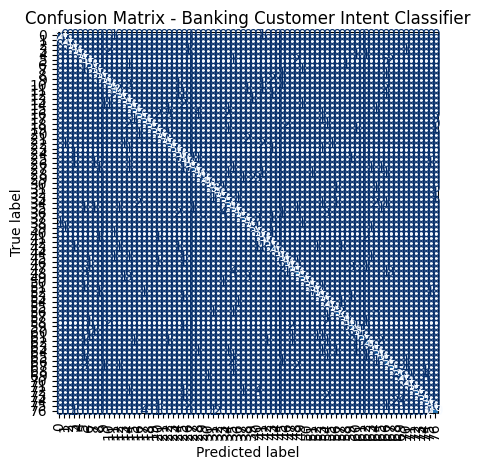

In [125]:
# Plot the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    labels=model_svm.classes_,
    cmap="Blues",
    xticks_rotation="vertical",
    colorbar=False
)

plt.title("Confusion Matrix - Banking Customer Intent Classifier")
plt.tight_layout()
plt.show()

In [126]:
import joblib

joblib.dump(model_svm, "customer_support_classifier.pkl")

print("LinearSVC pipeline saved successfully.")

LinearSVC pipeline saved successfully.
